# Homework 2: Heart Disease Prediction with Logistic Regression
**Course:** AI 240 Programming for Machine Learning

**Goal:** Build and evaluate a Logistic Regression classifier that predicts whether a patient has heart disease (`target`: 1 = yes, 0 = no) from 13 clinical features.

**Steps:** 1) Data exploration, 2) Data preprocessing, 3) Modeling, 4) Evaluation, 5) Conclusions.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve)

import warnings
# thal has a rare value (0) that can land only in the test fold; the encoder safely ignores it
warnings.filterwarnings("ignore", message="Found unknown categories")

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Data Exploration
### 1.1 Load the dataset
Put `heart.csv` (the file from the assignment) in the same folder as this notebook. If it is not found, the cell falls back to a public copy of the same dataset.

In [2]:
import os
if os.path.exists("heart.csv"):
    df = pd.read_csv("heart.csv")
else:
    url = "https://raw.githubusercontent.com/sharmaroshan/Heart-UCI-Dataset/master/heart.csv"
    df = pd.read_csv(url)

print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


### 1.2 Features and target
Column names follow the assignment's dataset description:

| Column | Meaning |
|---|---|
| age | Age in years |
| sex | 1 = male, 0 = female |
| cp | Chest pain type (4 values) |
| trestbps | Resting blood pressure |
| chol | Serum cholesterol (mg/dl) |
| fbs | Fasting blood sugar > 120 mg/dl (1 = true) |
| restecg | Resting ECG result (0, 1, 2) |
| thalach | Maximum heart rate achieved |
| exang | Exercise-induced angina (1 = yes) |
| oldpeak | ST depression induced by exercise relative to rest |
| slope | Slope of the peak exercise ST segment |
| ca | Number of major vessels (0-3) colored by fluoroscopy |
| thal | 0 = normal, 1 = fixed defect, 2 = reversible defect (as described in the assignment) |
| **target** | **Has heart disease (1 = yes, 0 = no): this is the variable we predict** |

In [3]:
target_col = "target"
feature_cols = [c for c in df.columns if c != target_col]
print("Target variable:", target_col)
print("Number of features:", len(feature_cols))
print("Features:", feature_cols)

Target variable: target
Number of features: 13
Features: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.366337,9.082101,29.0,47.5,55.0,61.0,77.0
sex,303.0,0.683168,0.466011,0.0,0.0,1.0,1.0,1.0
cp,303.0,0.966997,1.032052,0.0,0.0,1.0,2.0,3.0
trestbps,303.0,131.623762,17.538143,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.264026,51.830751,126.0,211.0,240.0,274.5,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.528053,0.525860,0.0,0.0,1.0,1.0,2.0
thalach,303.0,149.646865,22.905161,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


### 1.3 Missing values and duplicates

In [6]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Total missing values: 0
Duplicate rows: 1


### 1.4 Target distribution (is the data balanced?)

target
0    138
1    165
Name: count, dtype: int64
target
0    45.5 %
1    54.5 %
Name: count, dtype: str


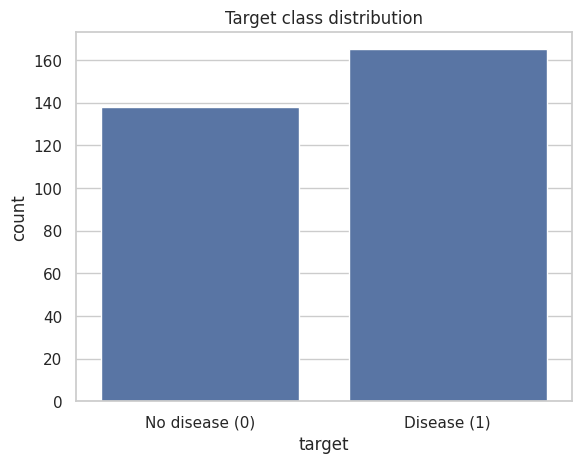

In [7]:
counts = df[target_col].value_counts().sort_index()
print(counts)
print((counts / len(df) * 100).round(1).astype(str) + " %")

ax = sns.countplot(x=target_col, data=df)
ax.set_xticks([0, 1])
ax.set_xticklabels(["No disease (0)", "Disease (1)"])
ax.set_title("Target class distribution")
plt.show()

### 1.5 Feature distributions

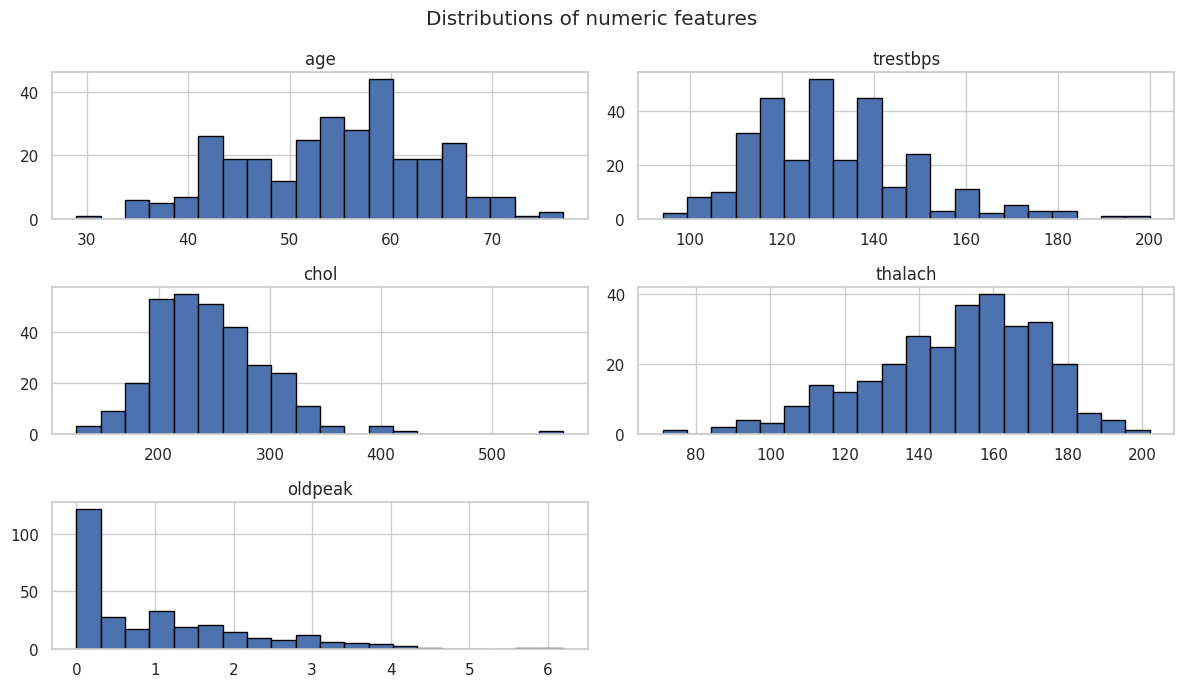

In [8]:
numeric_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
df[numeric_cols].hist(bins=20, figsize=(12, 7), edgecolor="black")
plt.suptitle("Distributions of numeric features")
plt.tight_layout()
plt.show()

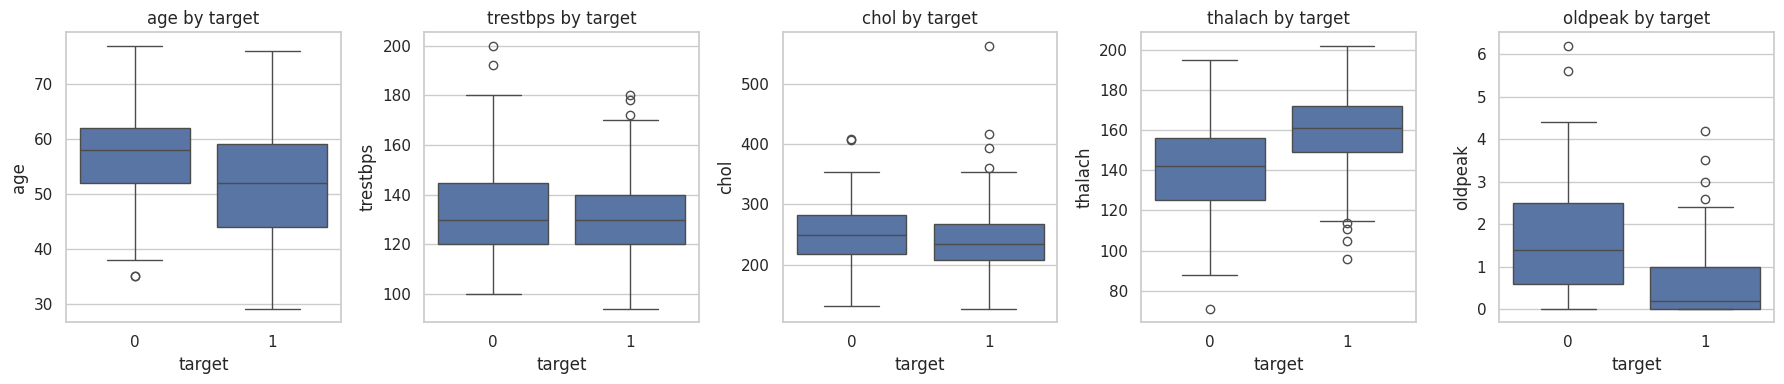

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(x=target_col, y=col, data=df, ax=ax)
    ax.set_title(f"{col} by target")
plt.tight_layout()
plt.show()

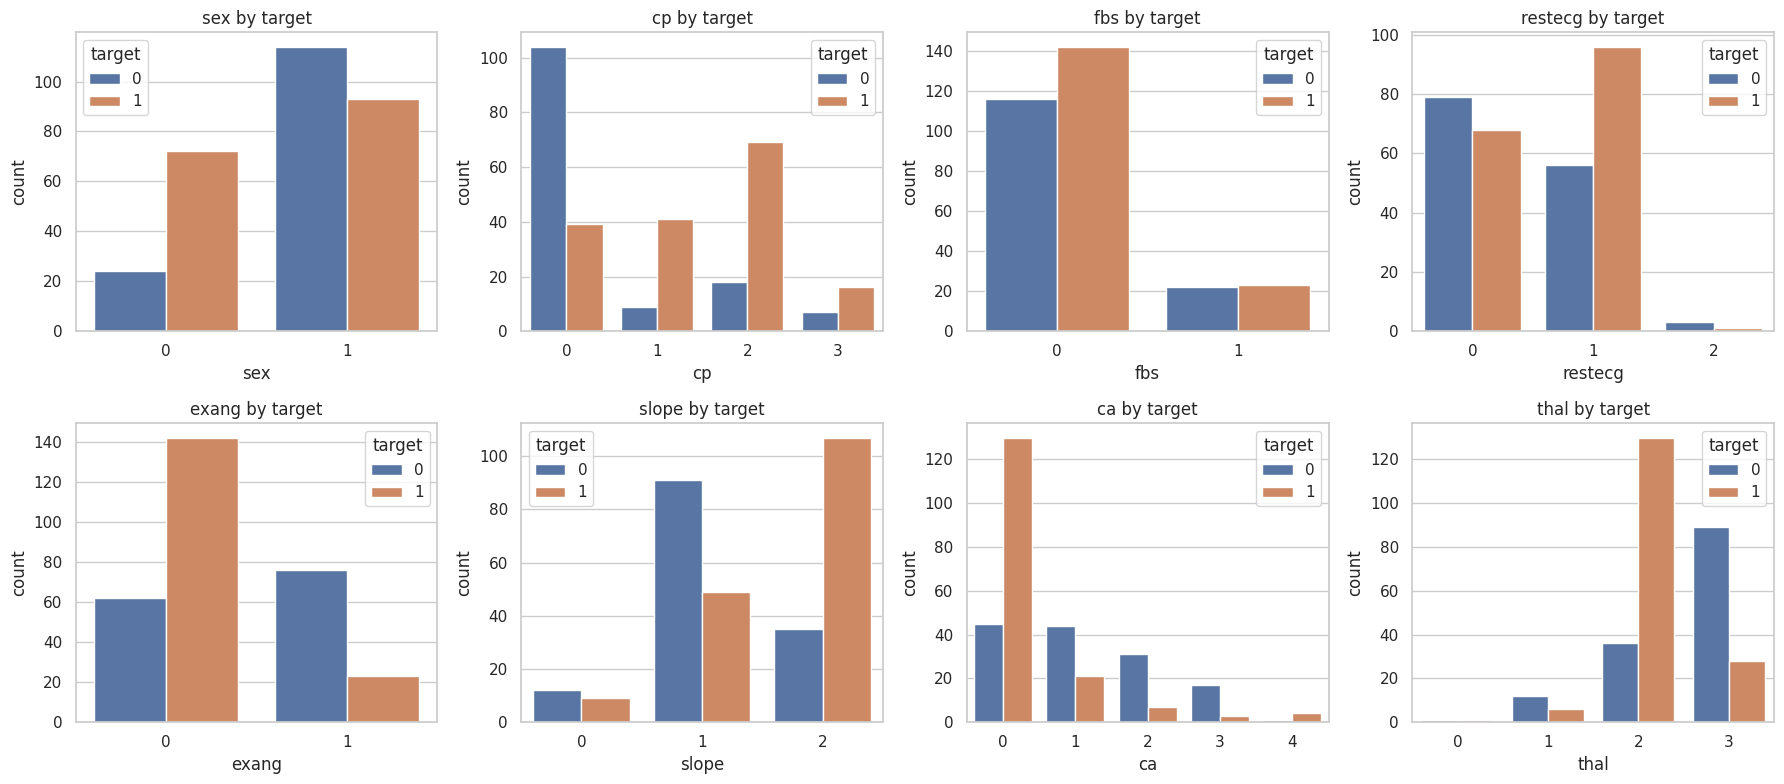

In [10]:
categorical_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), categorical_cols):
    sns.countplot(x=col, hue=target_col, data=df, ax=ax)
    ax.set_title(f"{col} by target")
plt.tight_layout()
plt.show()

### 1.6 Correlation with the target

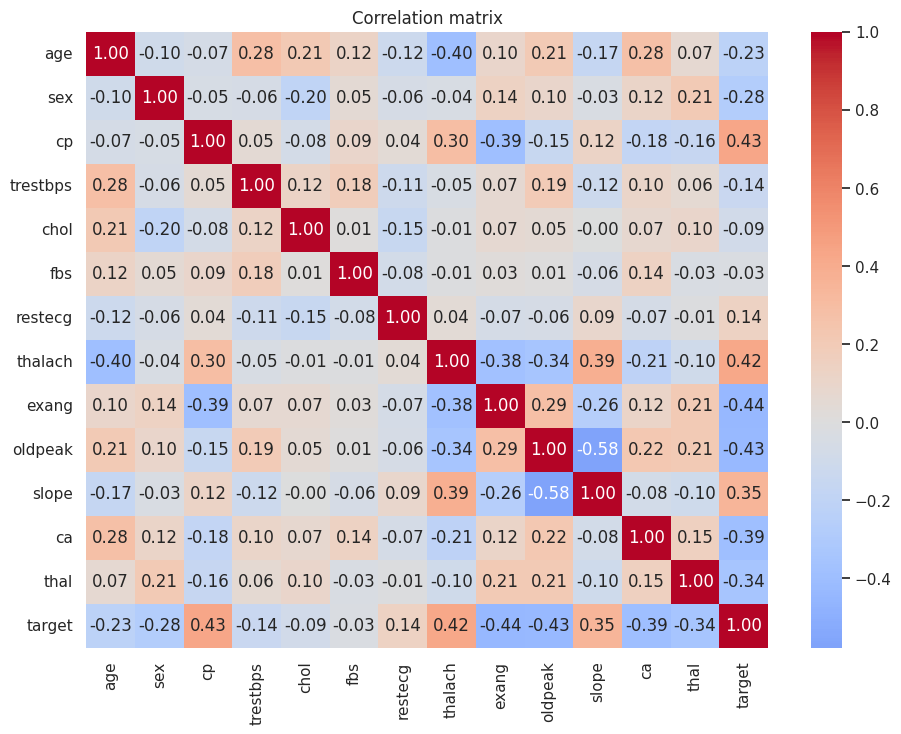

cp          0.434
thalach     0.422
slope       0.346
restecg     0.137
fbs        -0.028
chol       -0.085
trestbps   -0.145
age        -0.225
sex        -0.281
thal       -0.344
ca         -0.392
oldpeak    -0.431
exang      -0.437
Name: target, dtype: float64


In [11]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

print(corr[target_col].drop(target_col).sort_values(ascending=False).round(3))

## 2. Data Preprocessing
Steps:
1. **Remove duplicate rows** so the same patient does not appear in both train and test sets.
2. **Handle missing values**: this dataset has none, but the pipeline still includes an imputer so it would work on new data.
3. **Encode categorical features** with one-hot encoding: `cp`, `restecg`, `slope`, `thal` have no natural numeric order.
4. **Scale numeric features** with `StandardScaler` (mean 0, standard deviation 1) so features on large scales (like `chol`) do not dominate.
5. **Split into train and test sets** (80 / 20, stratified so both sets keep the same class ratio).

The encoder and scaler live inside a `Pipeline` and are fit on the **training data only**. This prevents data leakage from the test set.

In [12]:
df_clean = df.drop_duplicates().reset_index(drop=True)
print("Rows before:", len(df), "| after removing duplicates:", len(df_clean))

X = df_clean[feature_cols]
y = df_clean[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Train size:", X_train.shape, "| Test size:", X_test.shape)
print("Train class ratio:", y_train.value_counts(normalize=True).round(3).to_dict())
print("Test class ratio: ", y_test.value_counts(normalize=True).round(3).to_dict())

Rows before: 303 | after removing duplicates: 302
Train size: (241, 13) | Test size: (61, 13)
Train class ratio: {1: 0.544, 0: 0.456}
Test class ratio:  {1: 0.541, 0: 0.459}


In [13]:
numeric_features = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
categorical_features = ["cp", "restecg", "slope", "thal"]
binary_features = ["sex", "fbs", "exang"]   # already 0/1, kept as is

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first")),
])
binary_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features),
    ("bin", binary_pipe, binary_features),
])

## 3. Modeling: Logistic Regression
Logistic Regression models the probability of heart disease with the sigmoid function. A patient is predicted as class 1 when that probability is at least 0.5 (the default threshold).

In [14]:
model = Pipeline([
    ("preprocess", preprocessor),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Model trained.")
print("First 10 predicted probabilities:", np.round(y_prob[:10], 3))
print("First 10 predicted classes:      ", y_pred[:10])
print("First 10 actual classes:         ", y_test.values[:10])

Model trained.
First 10 predicted probabilities: [0.037 0.191 0.011 0.802 0.588 0.059 0.946 0.303 0.979 0.369]
First 10 predicted classes:       [0 0 0 1 1 0 1 0 1 0]
First 10 actual classes:          [0 0 0 0 0 0 1 0 1 0]


## 4. Evaluation

In [15]:
print(f"Accuracy  : {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision : {precision_score(y_test, y_pred):.3f}")
print(f"Recall    : {recall_score(y_test, y_pred):.3f}")
print(f"F1-score  : {f1_score(y_test, y_pred):.3f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, y_prob):.3f}")
print()
print(classification_report(y_test, y_pred, target_names=["No disease", "Disease"]))

Accuracy  : 0.787
Precision : 0.778
Recall    : 0.848
F1-score  : 0.812
ROC-AUC   : 0.872

              precision    recall  f1-score   support

  No disease       0.80      0.71      0.75        28
     Disease       0.78      0.85      0.81        33

    accuracy                           0.79        61
   macro avg       0.79      0.78      0.78        61
weighted avg       0.79      0.79      0.79        61



TN=20  FP=8  FN=5  TP=28
Specificity: 0.714


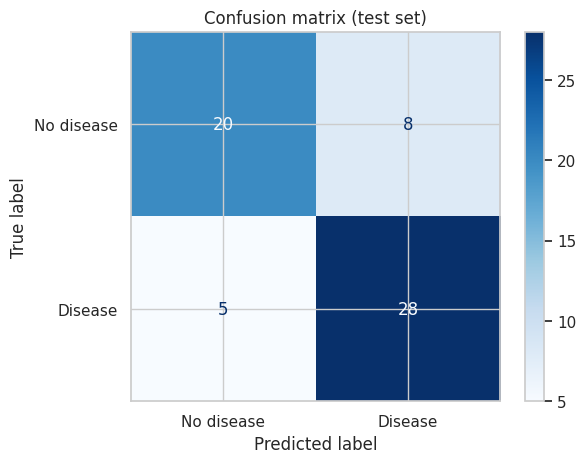

In [16]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"Specificity: {tn / (tn + fp):.3f}")

ConfusionMatrixDisplay(cm, display_labels=["No disease", "Disease"]).plot(cmap="Blues")
plt.title("Confusion matrix (test set)")
plt.show()

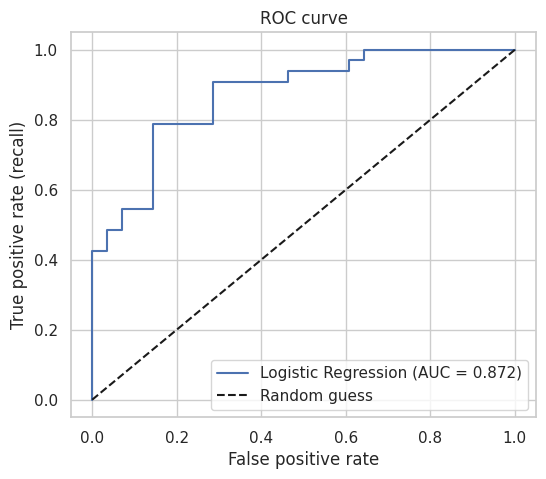

In [17]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc_score(y_test, y_prob):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("ROC curve")
plt.legend()
plt.show()

### 4.1 Cross-validation
A single train/test split on a small dataset can be lucky or unlucky. 5-fold stratified cross-validation on the training data gives a steadier estimate.

In [18]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring=metric)
    print(f"{metric:10s}: mean = {scores.mean():.3f}  (std = {scores.std():.3f})")

accuracy  : mean = 0.838  (std = 0.035)
precision : mean = 0.831  (std = 0.041)


recall    : mean = 0.885  (std = 0.042)
f1        : mean = 0.856  (std = 0.029)


roc_auc   : mean = 0.896  (std = 0.033)


### 4.2 Hyperparameter tuning
The regularization strength `C` controls how strongly the model is kept from overfitting (smaller `C` = stronger regularization). We search a few values using cross-validation on the training set, then check the best one on the test set.

In [19]:
param_grid = {"clf__C": [0.01, 0.1, 1, 10, 100]}
grid = GridSearchCV(model, param_grid, cv=cv, scoring="roc_auc")
grid.fit(X_train, y_train)

print("Best C:", grid.best_params_["clf__C"])
print(f"Best cross-validated ROC-AUC: {grid.best_score_:.3f}")

best = grid.best_estimator_
y_pred_best = best.predict(X_test)
y_prob_best = best.predict_proba(X_test)[:, 1]

print()
print("Tuned model on the test set:")
print(f"Accuracy : {accuracy_score(y_test, y_pred_best):.3f}")
print(f"Precision: {precision_score(y_test, y_pred_best):.3f}")
print(f"Recall   : {recall_score(y_test, y_pred_best):.3f}")
print(f"F1-score : {f1_score(y_test, y_pred_best):.3f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob_best):.3f}")

Best C: 1
Best cross-validated ROC-AUC: 0.896

Tuned model on the test set:
Accuracy : 0.787
Precision: 0.778
Recall   : 0.848
F1-score : 0.812
ROC-AUC  : 0.872


### 4.3 Which features matter?
Coefficients of a logistic regression show how each feature pushes the prediction. A positive coefficient raises the odds of heart disease and a negative one lowers them. Numeric features were scaled, so their coefficients are comparable to each other.

,feature,coefficient,odds_ratio
16,sex,-0.942,0.390
18,exang,-0.821,0.440
15,thal_3,-0.757,0.469
5,ca,-0.528,0.590
4,oldpeak,-0.507,0.602
2,chol,-0.500,0.607
11,slope_1,-0.340,0.712
13,thal_1,-0.201,0.818
1,trestbps,-0.181,0.834
10,restecg_2,-0.083,0.921


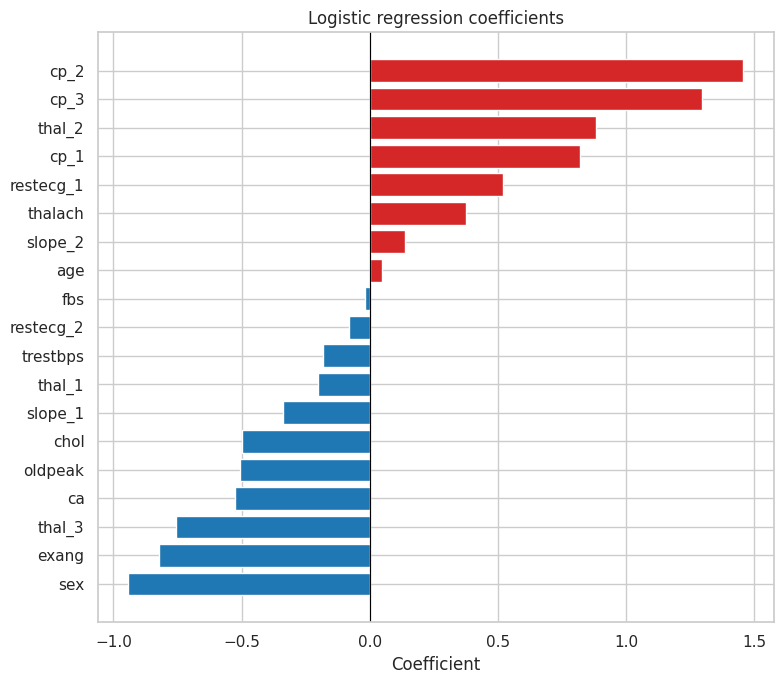

In [20]:
names = best.named_steps["preprocess"].get_feature_names_out()
names = [n.split("__", 1)[1] for n in names]
coefs = best.named_steps["clf"].coef_[0]

coef_df = pd.DataFrame({"feature": names, "coefficient": coefs,
                        "odds_ratio": np.exp(coefs)}).sort_values("coefficient")
display(coef_df.round(3))

plt.figure(figsize=(8, 7))
colors = ["tab:red" if c > 0 else "tab:blue" for c in coef_df["coefficient"]]
plt.barh(coef_df["feature"], coef_df["coefficient"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic regression coefficients")
plt.xlabel("Coefficient")
plt.tight_layout()
plt.show()

### 4.4 Effect of the decision threshold
In medicine, **missing a sick patient (false negative)** is usually worse than a false alarm. Lowering the threshold below 0.5 catches more sick patients (higher recall) but creates more false alarms (lower precision).

In [21]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred_t = (y_prob_best >= t).astype(int)
    rows.append({"threshold": t,
                 "accuracy": accuracy_score(y_test, pred_t),
                 "precision": precision_score(y_test, pred_t),
                 "recall": recall_score(y_test, pred_t),
                 "false_negatives": int(((pred_t == 0) & (y_test.values == 1)).sum())})
pd.DataFrame(rows).round(3)

,threshold,accuracy,precision,recall,false_negatives
0,0.3,0.754,0.714,0.909,3
1,0.4,0.820,0.789,0.909,3
2,0.5,0.787,0.778,0.848,5
3,0.6,0.803,0.862,0.758,8
4,0.7,0.754,0.846,0.667,11


## 5. Conclusions

**Data.** The dataset has 303 patients and 13 features, with no missing values and 1 duplicate row (removed). The classes are fairly balanced (about 54% disease, 46% no disease), so accuracy is a reasonable metric here.

**Model.** A Logistic Regression pipeline (one-hot encoding for categorical features, standard scaling for numeric ones) was trained on 80% of the data and tested on the remaining 20%.

**Results on the test set (61 patients):**

| Metric | Value |
|---|---|
| Accuracy | 0.787 |
| Precision | 0.778 |
| Recall | 0.848 |
| F1-score | 0.812 |
| Specificity | 0.714 |
| ROC-AUC | 0.872 |

The confusion matrix was TN = 20, FP = 8, FN = 5, TP = 28. 5-fold cross-validation on the training data gave similar, slightly higher numbers (accuracy 0.838, recall 0.885, ROC-AUC 0.896), so the model is stable and not just lucky on one split. The test set is small (61 rows), so one or two patients change the scores noticeably.

**Tuning.** Searching over the regularization strength `C` picked `C = 1`, which is the default, so tuning did not change the results.

**Threshold.** Lowering the threshold from 0.5 to 0.3-0.4 raised recall from 0.848 to 0.909 and cut false negatives from 5 to 3, at the cost of more false alarms. For a screening tool where a missed patient is the worse error, a lower threshold is worth considering.

**Important features.** Chest pain type (`cp`), exercise-induced angina (`exang`), `sex`, number of major vessels (`ca`), and `oldpeak` had the largest coefficients.

**Caveats.**
- The dataset is small, so these results should be confirmed on more data.
- The model is a learning exercise and must not be used for real medical decisions.
- In this widely shared copy of the dataset, `target = 1` goes with a *higher* maximum heart rate, *no* exercise angina and *lower* oldpeak. Medically, those usually point toward a *healthier* heart, so the label may be reversed in the source file. This follows the assignment's definition (1 = disease), and it does not change the model's accuracy, but it affects how the coefficient signs should be read.

**Possible improvements:** try other models (Random Forest, SVM), add feature engineering, and use a larger dataset.